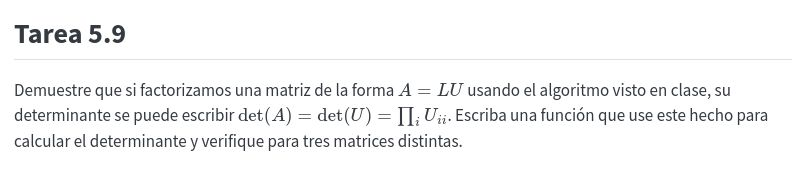

### Demostración

Si una matriz cuadrada \(A\) se puede factorizar como:

\[
**A=LU,**
\]

donde \(L\) es una matriz triangular inferior con unos en la diagonal y \(U\) es una matriz triangular superior, podemos usar las propiedades del determinante para calcularlo de una forma más sencilla.

Primero, sabemos que el determinante de un producto de matrices es igual al producto de sus determinantes:

equation.png

Como \(L\) es triangular inferior, su determinante es el producto de los elementos de su diagonal. En este caso, todos los elementos de la diagonal son iguales a uno, por lo que

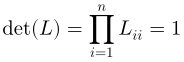

Entonces,

equation(2).png

Además, como \(U\) es una matriz triangular superior, su determinante también corresponde al producto de los elementos de su diagonal:

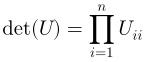

Por lo tanto, se obtiene el resultado que queríamos demostrar:

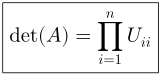

Esto permite calcular el determinante de \(A\) sin necesidad de desarrollar directamente el determinante original, sino multiplicando los elementos de la diagonal de \(U\), después de realizar la factorización LU.

In [10]:

#Tarea 5.9 Nicolás Ramírez

import numpy as np


In [6]:

def lufact(A):
    n = A.shape[0]

    #Partimos con L como identidad y U llena de ceros
    L = np.eye(n, dtype=float)
    U = np.zeros((n, n), dtype=float)
    Ak = A.copy().astype(float)

    for k in range(n - 1):
        #la fila k de U se obtiene de la matriz que tenemos
        U[k, :] = Ak[k, :]
        pivote = U[k, k]

        #Si el pivote es cero, no podemos seguir con este algoritmo
        if pivote == 0:
            raise ZeroDivisionError("Se encontró un pivote igual a cero")

        #calculamos los multiplicadores de la columna k de L
        L[:, k] = Ak[:, k] / pivote

        #Restamos la contribución que ya calculamos
        Ak = Ak - np.outer(L[:, k], U[k, :])

    U[n - 1, n - 1] = Ak[n - 1, n - 1] #el último elemento de la diagonal de U se calcula al final

    return L, U


In [7]:

def determinante_LU(A): #el determinante es el producto de la diagonal de U
    L, U = lufact(A)

    det_A = np.prod(np.diag(U))

    return det_A


In [9]:

A1 = np.array([
    [2, 1],
    [4, 3]
], dtype=float)

A2 = np.array([
    [3, 1, 1],
    [1, 2, 0],
    [2, 1, 4]
], dtype=float)

A3 = np.array([
    [4, 2, 1],
    [2, 5, 2],
    [1, 2, 4]
], dtype=float)

matrices = [A1, A2, A3]

for i, A in enumerate(matrices, start=1):
    det_lu = determinante_LU(A)

    # Comparamos con el determinante que calcula NumPy
    det_numpy = np.linalg.det(A)

    print(f"Matriz {i}:")
    print("Determinante por LU:", det_lu)
    print("Determinante por NumPy:", det_numpy)
    print("¿Coinciden?", np.isclose(det_lu, det_numpy))
    print()


Matriz 1:
Determinante por LU: 2.0
Determinante por NumPy: 2.0
¿Coinciden? True

Matriz 2:
Determinante por LU: 17.0
Determinante por NumPy: 17.0
¿Coinciden? True

Matriz 3:
Determinante por LU: 51.0
Determinante por NumPy: 51.0
¿Coinciden? True



In [5]:

L, U = lufact(A3)

print("Matriz L:")
print(L)

print("\nMatriz U:")
print(U)

print("\nProducto LU:")
print(L @ U)

print("\n¿LU es igual a A?")
print(np.allclose(L @ U, A3))


Matriz L:
[[1.    0.    0.   ]
 [0.5   1.    0.   ]
 [0.25  0.375 1.   ]]

Matriz U:
[[4.     2.     1.    ]
 [0.     4.     1.5   ]
 [0.     0.     3.1875]]

Producto LU:
[[4. 2. 1.]
 [2. 5. 2.]
 [1. 2. 4.]]

¿LU es igual a A?
True
